<a href="https://colab.research.google.com/github/petalpearl/HydroGuard-AI/blob/main/HydroGuardAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q scikit-learn imbalanced-learn xgboost lightgbm matplotlib seaborn torch

import os, zipfile, urllib.request, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("All dependencies imported successfully.")
print("Active Compute Device:", device)

All dependencies imported successfully.
Active Compute Device: cpu


In [ ]:
data_dir = "hydraulic_data"
zip_path = "hydraulic_systems.zip"
urls = [
    "https://archive.ics.uci.edu/static/public/447/condition+monitoring+of+hydraulic+systems.zip",
    "https://zenodo.org/records/1323611/files/data.zip?download=1"
]

if not os.path.exists(os.path.join(data_dir, "profile.txt")):
    os.makedirs(data_dir, exist_ok=True)
    for url in urls:
        try:
            print(f"Downloading real UCI dataset from: {url}")
            urllib.request.urlretrieve(url, zip_path)
            with zipfile.ZipFile(zip_path, "r") as z:
                z.extractall(data_dir)
            break
        except Exception as e:
            print(f"Mirror failed ({e}), trying fallback...")

for root, _, files in os.walk(data_dir):
    if "profile.txt" in files:
        data_dir = root
        break

sensors = [
    "PS1", "PS2", "PS3", "PS4", "PS5", "PS6", "EPS1",
    "FS1", "FS2", "TS1", "TS2", "TS3", "TS4", "VS1", "CE", "CP", "SE"
]

profile = pd.read_csv(os.path.join(data_dir, "profile.txt"), sep="\t", header=None)
profile.columns = ["Cooler", "Valve", "Pump_Leakage", "Accumulator", "Stable_Flag"]

print("=" * 60)
print("DATA UNDERSTANDING SUMMARY")
print("=" * 60)
print(f"Total Hydraulic Cycles : {len(profile)} (60 seconds each)")
print(f"Total Physical Sensors : {len(sensors)}")
print(f"Missing Target Labels  : {profile.isnull().sum().sum()}")

print("\nTarget Class Distribution — Internal Pump Leakage:")
class_counts = profile["Pump_Leakage"].value_counts().sort_index()
class_pct = (class_counts / len(profile) * 100).round(2)
display(pd.DataFrame({"Cycles": class_counts, "Share (%)": class_pct}))
print("Note: Class 0 (No Leak) dominates (>55%) while Classes 1 & 2 are minority classes -> SMOTE required.")

DATA UNDERSTANDING SUMMARY
Total Hydraulic Cycles : 2205 (60 seconds each)
Total Physical Sensors : 17
Missing Target Labels  : 0

Target Class Distribution — Internal Pump Leakage:


,Cycles,Share (%)
Pump_Leakage,,
0,1221,55.37
1,492,22.31
2,492,22.31


Note: Class 0 (No Leak) dominates (>55%) while Classes 1 & 2 are minority classes -> SMOTE required.


In [ ]:
tab_features = {}
seq_channels = []  # (2205, 60, 17) tensor for PyTorch LSTM

for s in sensors:
    arr = pd.read_csv(os.path.join(data_dir, f"{s}.txt"), sep="\t", header=None).values.astype(np.float32)
    n_cycles, n_steps = arr.shape

    # 1. Statistical signatures per 60-second cycle
    tab_features[f"{s}_mean"]  = arr.mean(axis=1)
    tab_features[f"{s}_std"]   = arr.std(axis=1)
    tab_features[f"{s}_min"]   = arr.min(axis=1)
    tab_features[f"{s}_max"]   = arr.max(axis=1)
    tab_features[f"{s}_drift"] = arr[:, -1] - arr[:, 0]

    # 2. Downsample/align every sensor to 1 Hz (60 time steps) for LSTM
    arr_1hz = arr.reshape(n_cycles, 60, -1).mean(axis=2) if n_steps > 60 else arr
    seq_channels.append(arr_1hz)

X_raw = pd.DataFrame(tab_features)

# 3. Mechanical Domain Features (Fluid Power Physics)
X_raw["Hydraulic_Power_Proxy"] = X_raw["PS1_mean"] * X_raw["FS1_mean"]          # P x Q
X_raw["Pressure_Drop_1_2"]     = X_raw["PS1_mean"] - X_raw["PS2_mean"]          # Line loss
X_raw["Thermal_Delta_T"]       = X_raw["TS4_mean"] - X_raw["TS1_mean"]          # Heat buildup
X_raw["Power_per_Flow"]        = X_raw["EPS1_mean"] / (X_raw["FS1_mean"] + 1e-5) # Pumping efficiency proxy

X_seq_full = np.stack(seq_channels, axis=-1)  # Shape: (2205, 60, 17)
y_full = profile["Pump_Leakage"].values.astype(int)

print("=" * 60)
print("FEATURE ENGINEERING COMPLETE")
print("=" * 60)
print(f"Raw Tabular Feature Matrix : {X_raw.shape} (85 sensor stats + 4 physics features)")
print(f"LSTM Sequence Tensor       : {X_seq_full.shape}")
print(f"Missing Engineered Values  : {X_raw.isnull().sum().sum()}")
display(X_raw[["PS1_mean", "EPS1_mean", "FS1_mean", "Hydraulic_Power_Proxy", "Power_per_Flow"]].head(4).round(2))

FEATURE ENGINEERING COMPLETE
Raw Tabular Feature Matrix : (2205, 89) (85 sensor stats + 4 physics features)
LSTM Sequence Tensor       : (2205, 60, 17)
Missing Engineered Values  : 0


,PS1_mean,EPS1_mean,FS1_mean,Hydraulic_Power_Proxy,Power_per_Flow
0,160.669998,2538.979980,6.71,1078.089966,378.399994
1,160.600006,2531.570068,6.72,1078.500000,376.980011
2,160.350006,2519.979980,6.72,1077.300049,375.079987
3,160.190002,2511.610107,6.72,1076.550049,373.720001


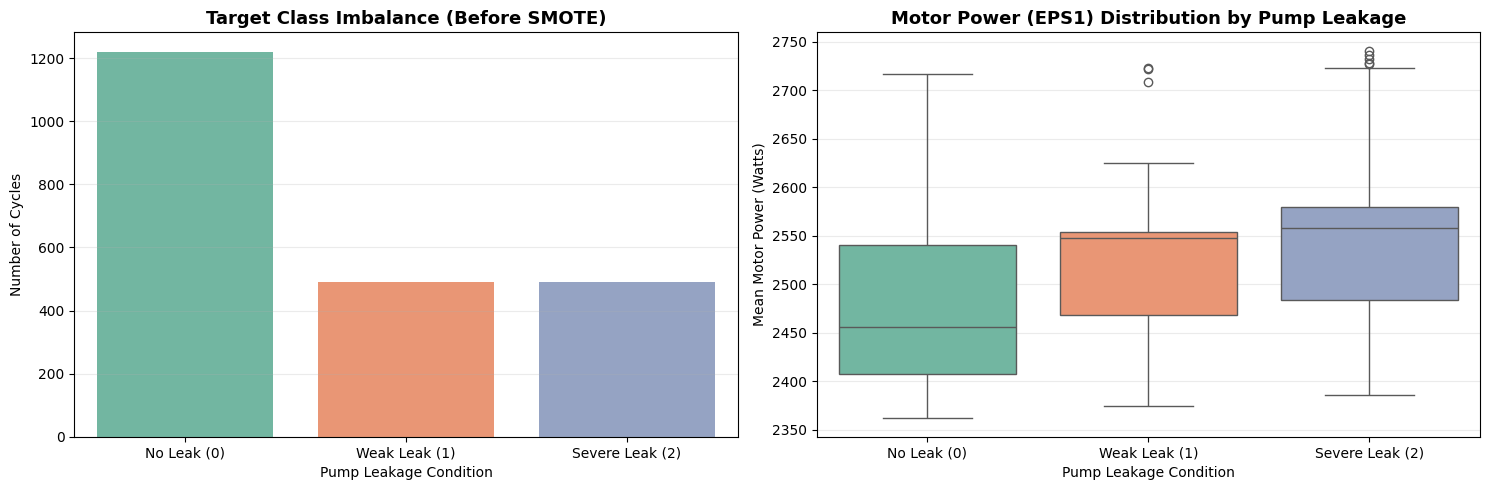

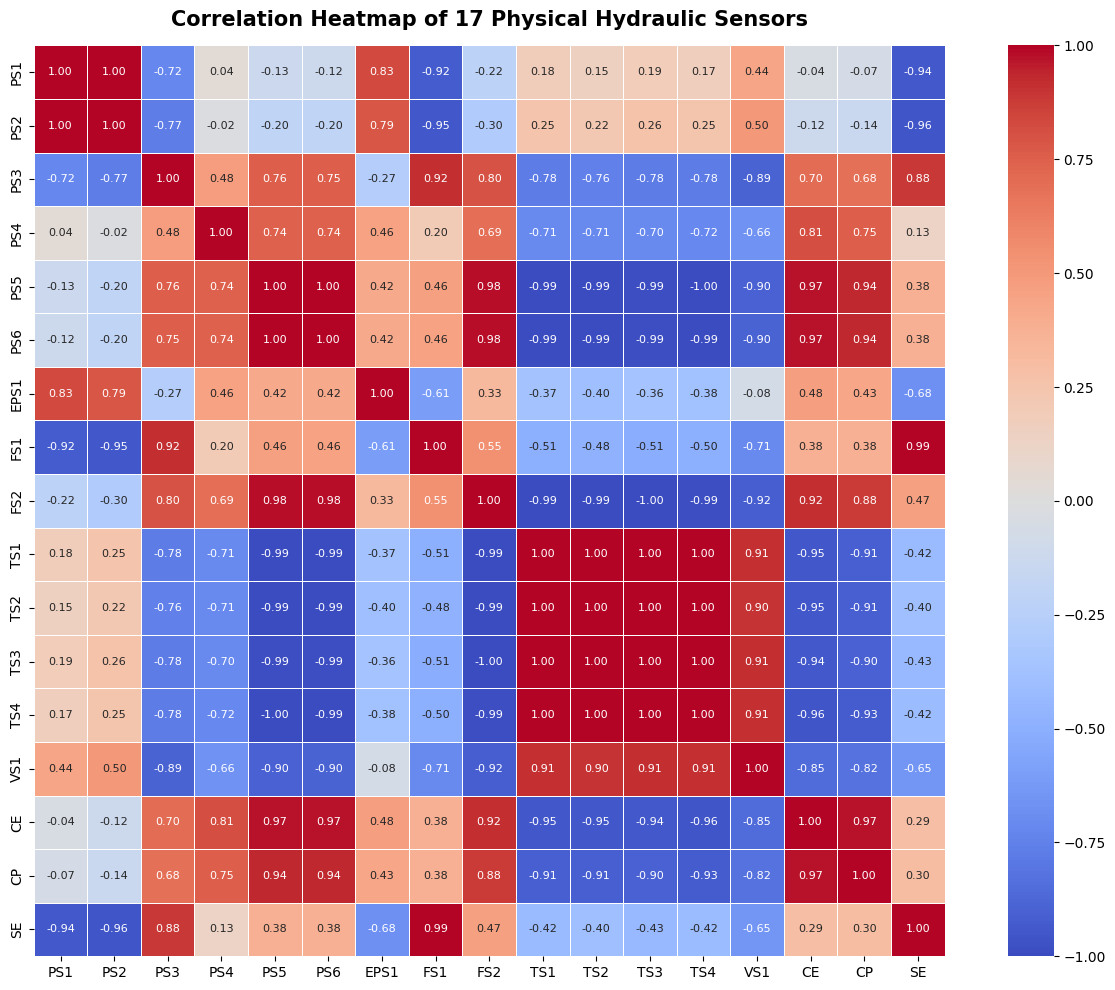

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Class Imbalance Bar Plot
labels_map = ["No Leak (0)", "Weak Leak (1)", "Severe Leak (2)"]
sns.countplot(x=y_full, palette="Set2", ax=axes[0])
axes[0].set_xticklabels(labels_map)
axes[0].set_title("Target Class Imbalance (Before SMOTE)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Pump Leakage Condition")
axes[0].set_ylabel("Number of Cycles")
axes[0].grid(axis="y", alpha=0.25)

# 2. Motor Power vs Pump Leakage Boxplot
sns.boxplot(x=y_full, y=X_raw["EPS1_mean"], palette="Set2", ax=axes[1])
axes[1].set_xticklabels(labels_map)
axes[1].set_title("Motor Power (EPS1) Distribution by Pump Leakage", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Pump Leakage Condition")
axes[1].set_ylabel("Mean Motor Power (Watts)")
axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# 3. Sensor Mean Correlation Heatmap (17 Sensors)
mean_cols = [f"{s}_mean" for s in sensors]
corr_matrix = X_raw[mean_cols].corr()
corr_matrix.index = [c.replace("_mean", "") for c in corr_matrix.index]
corr_matrix.columns = [c.replace("_mean", "") for c in corr_matrix.columns]

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, vmin=-1, vmax=1, linewidths=0.5, square=True, annot_kws={"size": 8}
)
plt.title("Correlation Heatmap of 17 Physical Hydraulic Sensors", fontsize=15, fontweight="bold", pad=14)
plt.tight_layout()
plt.show()

In [ ]:
# Stratified 70% Train / 15% Validation / 15% Test Split
idx = np.arange(len(y_full))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y_full, random_state=42)
idx_val,   idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y_full[idx_temp], random_state=42)

X_train_raw, y_train = X_raw.iloc[idx_train].copy(), y_full[idx_train]
X_val_raw,   y_val   = X_raw.iloc[idx_val].copy(),   y_full[idx_val]
X_test_raw,  y_test  = X_raw.iloc[idx_test].copy(),  y_full[idx_test]

# ==========================================================
# STEP 6A: REDUCING MODEL COMPLEXITY — COLLINEAR FEATURE PRUNING
# ==========================================================
# Drop redundant features with |correlation| > 0.95 (fit strictly on Training set!)
corr_train = X_train_raw.corr().abs()
upper_tri = corr_train.where(np.triu(np.ones(corr_train.shape), k=1).astype(bool))
to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > 0.95)]

X_train_pruned = X_train_raw.drop(columns=to_drop)
X_val_pruned   = X_val_raw.drop(columns=to_drop)
X_test_pruned  = X_test_raw.drop(columns=to_drop)

# Standardize features (fit ONLY on Training set)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_pruned)
X_val_sc   = scaler.transform(X_val_pruned)
X_test_sc  = scaler.transform(X_test_pruned)

# ==========================================================
# APPLY SMOTE STRICTLY ON TRAINING SET (ZERO DATA LEAKAGE)
# ==========================================================
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_sc, y_train)

print("=" * 65)
print("FEATURE PRUNING, SCALING & SMOTE BALANCING COMPLETE")
print("=" * 65)
print(f"Original Features             : {X_train_raw.shape[1]}")
print(f"Dropped Collinear (|r|>0.95)  : {len(to_drop)}")
print(f"Final Selected Features       : {X_train_pruned.shape[1]}")

smote_df = pd.DataFrame({
    "Before SMOTE (Train)": pd.Series(y_train).value_counts().sort_index(),
    "After SMOTE (Train)":  pd.Series(y_train_smote).value_counts().sort_index(),
    "Validation (Untouched)": pd.Series(y_val).value_counts().sort_index(),
    "Test (Untouched)":       pd.Series(y_test).value_counts().sort_index()
})
smote_df.index = ["No Leak (0)", "Weak Leak (1)", "Severe Leak (2)"]
display(smote_df)

FEATURE PRUNING, SCALING & SMOTE BALANCING COMPLETE
Original Features             : 89
Dropped Collinear (|r|>0.95)  : 48
Final Selected Features       : 41


,Before SMOTE (Train),After SMOTE (Train),Validation (Untouched),Test (Untouched)
No Leak (0),855,855,183,183
Weak Leak (1),344,855,74,74
Severe Leak (2),344,855,74,74


In [ ]:
# Demonstrate how controlling tree complexity reduces Train-Val overfitting gap
unconstrained_rf = RandomForestClassifier(n_estimators=200, max_depth=None, min_samples_leaf=1, random_state=42, n_jobs=-1)
unconstrained_rf.fit(X_train_smote, y_train_smote)

regularized_rf = RandomForestClassifier(
    n_estimators=200, max_depth=8, min_samples_leaf=8, max_features="sqrt", random_state=42, n_jobs=-1
)
regularized_rf.fit(X_train_smote, y_train_smote)

overfit_check = pd.DataFrame([
    {
        "Configuration": "Unconstrained RF (High Complexity)",
        "Train Acc (%)": accuracy_score(y_train_smote, unconstrained_rf.predict(X_train_smote)) * 100,
        "Val Acc (%)":   accuracy_score(y_val, unconstrained_rf.predict(X_val_sc)) * 100,
        "Overfit Gap (%)": (accuracy_score(y_train_smote, unconstrained_rf.predict(X_train_smote)) -
                            accuracy_score(y_val, unconstrained_rf.predict(X_val_sc))) * 100
    },
    {
        "Configuration": "Regularized RF (Pruned Depth + Min Leaf)",
        "Train Acc (%)": accuracy_score(y_train_smote, regularized_rf.predict(X_train_smote)) * 100,
        "Val Acc (%)":   accuracy_score(y_val, regularized_rf.predict(X_val_sc)) * 100,
        "Overfit Gap (%)": (accuracy_score(y_train_smote, regularized_rf.predict(X_train_smote)) -
                            accuracy_score(y_val, regularized_rf.predict(X_val_sc))) * 100
    }
])

print("=" * 65)
print("REDUCING MODEL COMPLEXITY — OVERFITTING CHECK")
print("=" * 65)
display(overfit_check.round(3))

REDUCING MODEL COMPLEXITY — OVERFITTING CHECK


,Configuration,Train Acc (%),Val Acc (%),Overfit Gap (%)
0,Unconstrained RF (High Complexity),100.000,99.094,0.906
1,Regularized RF (Pruned Depth + Min Leaf),99.844,99.094,0.750


In [ ]:
# All models include explicit complexity controls to prevent overfitting:
# - Logistic Regression: L2 penalty (C=0.5)
# - Random Forest: max_depth=10, min_samples_leaf=5
# - XGBoost: max_depth=4, reg_lambda=5.0, subsample=0.8, colsample_bytree=0.8
# - LightGBM: max_depth=5, num_leaves=20, min_child_samples=20, reg_lambda=5.0
# - PyTorch LSTM: dropout=0.3, weight_decay=1e-4, Early Stopping

ml_models = {
    "Logistic Regression (L2)": LogisticRegression(C=0.5, max_iter=1500, random_state=42),
    "Random Forest (Regularized)": RandomForestClassifier(
        n_estimators=250, max_depth=10, min_samples_leaf=5, max_features="sqrt", random_state=42, n_jobs=-1
    ),
    "XGBoost (Regularized)": XGBClassifier(
        n_estimators=250, learning_rate=0.05, max_depth=4, min_child_weight=5,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, eval_metric="mlogloss", random_state=42, n_jobs=-1
    ),
    "LightGBM (Regularized)": LGBMClassifier(
        n_estimators=250, learning_rate=0.05, max_depth=5, num_leaves=20,
        min_child_samples=20, subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0,
        random_state=42, verbose=-1, n_jobs=-1
    )
}

results = []
fitted_models = {}

for name, model in ml_models.items():
    model.fit(X_train_smote, y_train_smote)
    tr_preds = model.predict(X_train_smote)
    va_preds = model.predict(X_val_sc)
    fitted_models[name] = model
    results.append({
        "Model": name,
        "Train Acc (%)": accuracy_score(y_train_smote, tr_preds) * 100,
        "Val Acc (%)":   accuracy_score(y_val, va_preds) * 100,
        "Overfit Gap (%)": (accuracy_score(y_train_smote, tr_preds) - accuracy_score(y_val, va_preds)) * 100,
        "Val Macro F1":  f1_score(y_val, va_preds, average="macro")
    })

# --- Train 2-Layer PyTorch LSTM (with Dropout + Weight Decay + Early Stopping) ---
seq_mean = X_seq_full[idx_train].mean(axis=(0, 1), keepdims=True)
seq_std  = X_seq_full[idx_train].std(axis=(0, 1), keepdims=True) + 1e-6

Xs_tr = torch.tensor((X_seq_full[idx_train] - seq_mean) / seq_std, dtype=torch.float32)
Xs_va = torch.tensor((X_seq_full[idx_val]   - seq_mean) / seq_std, dtype=torch.float32)
Xs_te = torch.tensor((X_seq_full[idx_test]  - seq_mean) / seq_std, dtype=torch.float32)

# Class weights for LSTM to handle imbalance without distorting 3D time-series sequences
cls_counts = np.bincount(y_train)
cls_weights = torch.tensor(len(y_train) / (3.0 * cls_counts), dtype=torch.float32).to(device)

train_loader = DataLoader(TensorDataset(Xs_tr, torch.tensor(y_train, dtype=torch.long)), batch_size=32, shuffle=True)

class RegularizedHydroLSTM(nn.Module):
    def __init__(self, n_features=17, hidden_dim=64, num_classes=3):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden_dim, num_layers=2, batch_first=True, dropout=0.3)
        self.head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, 32),
            nn.ReLU(),
            nn.Linear(32, num_classes)
        )
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.head(out[:, -1, :])

lstm_model = RegularizedHydroLSTM().to(device)
criterion = nn.CrossEntropyLoss(weight=cls_weights)
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.0025, weight_decay=1e-4)

best_val_acc, best_lstm_state = 0.0, None
train_hist, val_hist = [], []

for epoch in range(30):
    lstm_model.train()
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        loss = criterion(lstm_model(bx), by)
        loss.backward()
        optimizer.step()

    lstm_model.eval()
    with torch.no_grad():
        tr_acc = accuracy_score(y_train, lstm_model(Xs_tr.to(device)).argmax(dim=1).cpu().numpy()) * 100
        va_preds_l = lstm_model(Xs_va.to(device)).argmax(dim=1).cpu().numpy()
        va_acc = accuracy_score(y_val, va_preds_l) * 100
        train_hist.append(tr_acc)
        val_hist.append(va_acc)
        if va_acc > best_val_acc:
            best_val_acc = va_acc
            best_lstm_state = {k: v.cpu().clone() for k, v in lstm_model.state_dict().items()}

lstm_model.load_state_dict(best_lstm_state)
lstm_model.eval()
with torch.no_grad():
    lstm_tr_preds = lstm_model(Xs_tr.to(device)).argmax(dim=1).cpu().numpy()
    lstm_va_preds = lstm_model(Xs_va.to(device)).argmax(dim=1).cpu().numpy()

results.append({
    "Model": "PyTorch LSTM (Dropout + L2)",
    "Train Acc (%)": accuracy_score(y_train, lstm_tr_preds) * 100,
    "Val Acc (%)":   accuracy_score(y_val, lstm_va_preds) * 100,
    "Overfit Gap (%)": (accuracy_score(y_train, lstm_tr_preds) - accuracy_score(y_val, lstm_va_preds)) * 100,
    "Val Macro F1":  f1_score(y_val, lstm_va_preds, average="macro")
})

print("All 5 regularized models trained successfully.")

All 5 regularized models trained successfully.


MODEL COMPARISON LEADERBOARD (VALIDATION SET)


,Model,Train Acc (%),Val Acc (%),Overfit Gap (%),Val Macro F1
0,Random Forest (Regularized),99.961,99.094,0.867,0.988
1,LightGBM (Regularized),100.000,99.094,0.906,0.986
2,XGBoost (Regularized),99.922,99.094,0.828,0.988
3,Logistic Regression (L2),98.558,96.677,1.881,0.960
4,PyTorch LSTM (Dropout + L2),83.215,84.592,-1.378,0.818



--> SELECTED BEST MODEL: Random Forest (Regularized)


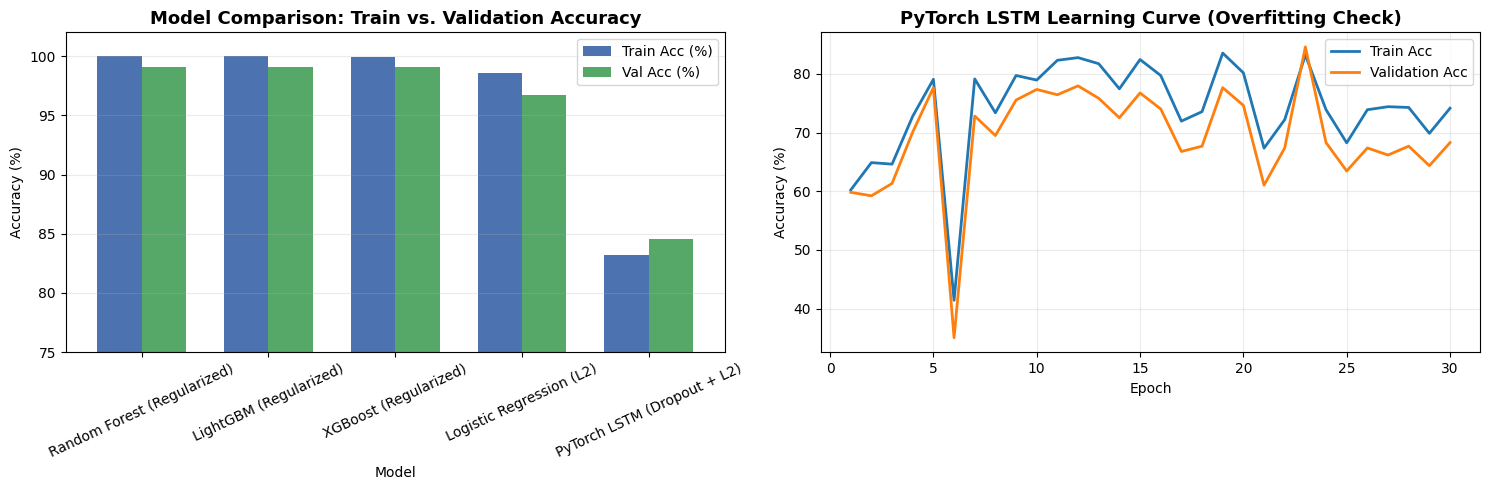

In [ ]:
comp_df = pd.DataFrame(results).sort_values("Val Acc (%)", ascending=False).reset_index(drop=True)
best_model_name = comp_df.loc[0, "Model"]

print("=" * 65)
print("MODEL COMPARISON LEADERBOARD (VALIDATION SET)")
print("=" * 65)
display(comp_df.round(3))
print(f"\n--> SELECTED BEST MODEL: {best_model_name}")

# Plot Model Comparison + LSTM Train vs Val Learning Curve
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

comp_plot = comp_df.set_index("Model")[["Train Acc (%)", "Val Acc (%)"]]
comp_plot.plot(kind="bar", ax=axes[0], color=["#4c72b0", "#55a868"], width=0.7)
axes[0].set_title("Model Comparison: Train vs. Validation Accuracy", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(75, 102)
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.25)

axes[1].plot(range(1, len(train_hist) + 1), train_hist, label="Train Acc", lw=2)
axes[1].plot(range(1, len(val_hist) + 1), val_hist, label="Validation Acc", lw=2)
axes[1].set_title("PyTorch LSTM Learning Curve (Overfitting Check)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

FINAL HELD-OUT TEST SET RESULTS — Random Forest (Regularized)
Test Accuracy  : 98.19%
Test Macro F1  : 0.9742

Detailed Classification Report:
                 precision    recall  f1-score   support

    No Leak (0)       0.99      1.00      1.00       183
  Weak Leak (1)       0.96      0.96      0.96        74
Severe Leak (2)       0.97      0.96      0.97        74

       accuracy                           0.98       331
      macro avg       0.98      0.97      0.97       331
   weighted avg       0.98      0.98      0.98       331



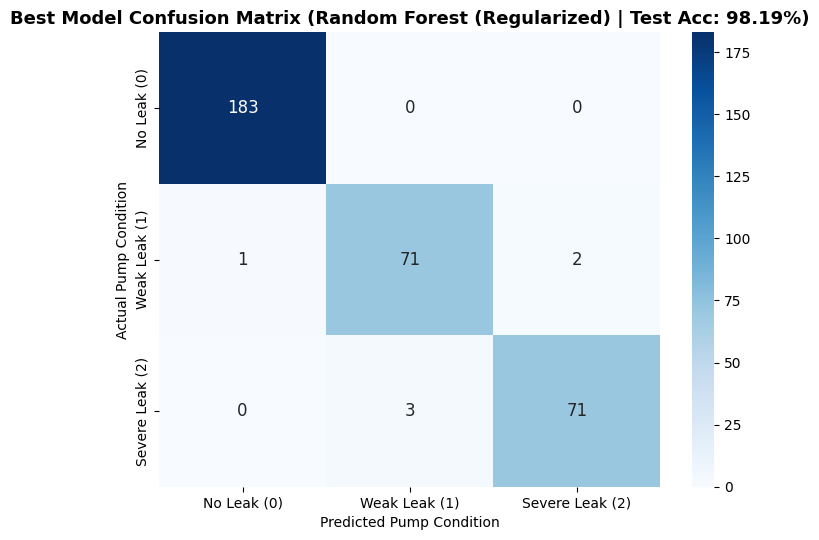


LIVE PLANT-FLOOR DIAGNOSTIC ALERT TABLE (LATEST 10 CYCLES):


,Cycle ID,Actual Condition,Predicted Condition,Confidence (%),Maintenance Alert
0,236,Severe Leak (2),Severe Leak (2),71.18,CRITICAL (Severe Leak)
1,380,Severe Leak (2),Weak Leak (1),50.34,WARNING (Weak Leak)
2,485,Severe Leak (2),Severe Leak (2),93.46,CRITICAL (Severe Leak)
3,971,Severe Leak (2),Severe Leak (2),79.87,CRITICAL (Severe Leak)
4,252,Weak Leak (1),Weak Leak (1),70.22,WARNING (Weak Leak)
5,231,Severe Leak (2),Severe Leak (2),79.97,CRITICAL (Severe Leak)
6,1817,Severe Leak (2),Severe Leak (2),94.67,CRITICAL (Severe Leak)
7,40,No Leak (0),No Leak (0),93.10,HEALTHY
8,639,Severe Leak (2),Severe Leak (2),61.69,CRITICAL (Severe Leak)
9,1369,Severe Leak (2),Severe Leak (2),79.01,CRITICAL (Severe Leak)


In [ ]:
# Evaluate the winning model strictly on the untouched Test Set
if best_model_name == "PyTorch LSTM (Dropout + L2)":
    lstm_model.eval()
    with torch.no_grad():
        test_probs = torch.softmax(lstm_model(Xs_te.to(device)), dim=1).cpu().numpy()
        test_preds = test_probs.argmax(axis=1)
else:
    best_model = fitted_models[best_model_name]
    test_probs = best_model.predict_proba(X_test_sc)
    test_preds = best_model.predict(X_test_sc)

test_acc = accuracy_score(y_test, test_preds) * 100
test_f1  = f1_score(y_test, test_preds, average="macro")

print("=" * 65)
print(f"FINAL HELD-OUT TEST SET RESULTS — {best_model_name}")
print("=" * 65)
print(f"Test Accuracy  : {test_acc:.2f}%")
print(f"Test Macro F1  : {test_f1:.4f}\n")
print("Detailed Classification Report:")
print(classification_report(y_test, test_preds, target_names=["No Leak (0)", "Weak Leak (1)", "Severe Leak (2)"]))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, test_preds, labels=[0, 1, 2])
plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Leak (0)", "Weak Leak (1)", "Severe Leak (2)"],
    yticklabels=["No Leak (0)", "Weak Leak (1)", "Severe Leak (2)"],
    annot_kws={"size": 12}
)
plt.title(f"Best Model Confusion Matrix ({best_model_name} | Test Acc: {test_acc:.2f}%)", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Pump Condition")
plt.ylabel("Actual Pump Condition")
plt.tight_layout()
plt.show()

# Live Plant-Floor Fault Alert Table (Latest 10 Test Cycles)
status_map = {0: "HEALTHY", 1: "WARNING (Weak Leak)", 2: "CRITICAL (Severe Leak)"}
class_names = ["No Leak (0)", "Weak Leak (1)", "Severe Leak (2)"]

live_alerts = pd.DataFrame({
    "Cycle ID": idx_test[-10:],
    "Actual Condition": [class_names[c] for c in y_test[-10:]],
    "Predicted Condition": [class_names[c] for c in test_preds[-10:]],
    "Confidence (%)": test_probs[-10:].max(axis=1) * 100,
    "Maintenance Alert": [status_map[c] for c in test_preds[-10:]]
})
print("\nLIVE PLANT-FLOOR DIAGNOSTIC ALERT TABLE (LATEST 10 CYCLES):")
display(live_alerts.round(2))